## Prueba
ACTIVIDAD PRÁCTICO EXPERIMENTAL EN EL ENTORNO ACADÉMICO

Objetivo
Desarrollar un proceso completo de Machine Learning para construir un modelo de regresión lineal múltiple capaz de estimar los gastos médicos (charges) a partir de las características disponibles en el conjunto de datos, aplicando análisis exploratorio, tratamiento de datos, detección de valores atípicos, transformación de variables, selección de atributos, validación, entrenamiento, evaluación y predicción de nuevas observaciones.

Descripción de la actividad: 
Una organización relacionada con servicios de salud desea analizar qué características de sus registros están asociadas con los costos médicos y construir un modelo que permita estimar el valor de charges para nuevas observaciones.
El dataset proporciona edad, sexo, índice de masa corporal (BMI), número de dependientes, condición de fumador, región y gastos médicos.
El estudiante deberá desarrollar un notebook que resuelva las siguientes etapas.
El conjunto de dato se desde kaggle debe ser automatizado la descarga desde el mismo lenguaje

Recursos necesarios
1.	Conjunto de datos descargados desde kaggle insurance.csv https://www.kaggle.com/datasets/mirichoi0218/insurance
2.	Ananconda
3.	Generar el pipelin detallada de cada una de las fases dlproyecto 

Desarrollo: 
1.	Carga y comprensión de los datos — 10 %
2.	EDA y calidad de los datos — 15 %
3.	Detección de outliers — 10 %
4.	Preparación de variables — 10 %
5.	Normalización o estandarización — 10 %
6.	Selección de atributos — 10 %
7.	Validación de datos — 10 %
8.	Entrenamiento mediante Regresión Lineal — 10 %
9.	Evaluación — 10 %
10.	Predicción con nuevos datos — 5 %


In [19]:
## FASE 1 — Comprensión de los datos

In [1]:
!pip install kagglehub

In [52]:
##Importamos las librerias

## Importamos la librería que nos permitirá trabajar con datasets de Kaggle.
import kagglehub
## Nos permitirá trabajar con nuestro dataset como si fuera una tabla
import pandas as pd
##Lo utilizaremos para operaciones numéricas.
import numpy as np
## Matplotlib nos permitirá crear gráficos.
import matplotlib.pyplot as plt
## La utilizaremos principalmente para gráficos estadísticos.
import seaborn as sns
## libreria para trabajar con archivos en el sistema
import os
##
from sklearn.model_selection import train_test_split
##
from sklearn.compose import ColumnTransformer
##
from sklearn.preprocessing import OneHotEncoder, StandardScaler
##
from sklearn.pipeline import Pipeline
##
from sklearn.linear_model import LinearRegression
##
from sklearn.feature_selection import SelectKBest, f_regression
##
from sklearn import metrics

In [4]:
## Descargar el dataset
## identifica el dataset de Kaggle
ruta = kagglehub.dataset_download(
    "mirichoi0218/insurance"
)

In [49]:
## Buscar el archivo CSV
print(os.listdir(ruta))

['insurance.csv']


In [6]:
## Cargar insurance.csv
archivo = os.path.join(ruta, "insurance.csv")
## Lee un archivo CSV y conviértelo en un DataFrame de pandas
df = pd.read_csv(archivo)

In [7]:
## verificar si el data frame se cargo correctamente 
# el head nos permite visualizar los primeros 5 filas de df
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [9]:
## Saber cuántas filas y columnas tenemos
df.shape

(1338, 7)

In [12]:
## Conocer los nombres de las columnas
## Esto nos permite saber qué variables tenemos
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

In [15]:
## Información general
## Nos permite observar:
## cantidad de registros
## nombres de columnas
## tipos de datos
## valores no nulos
## memoria utilizada
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [17]:
## Estadísticas descriptivas
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [18]:
## FASE 2 — EDA y calidad de los datos

In [21]:
## Buscar valores faltantes
df.isnull().sum() ## nos dice cuántos valores faltantes tiene cada columna

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [22]:
## Buscar registros duplicados
df.duplicated().sum()

np.int64(1)

In [23]:
## Eliminar duplicados
df = df.drop_duplicates()

In [24]:
## ahora ya no tenemos archivos duplicadodos
df.duplicated().sum()

np.int64(0)

In [54]:
## Revisar nuevamente el tamaño
print("Nuevo tamaño del dataset:", df.shape)

Nuevo tamaño del dataset: (1337, 7)


In [56]:
## Analizar las variables categóricas

## categoria mujer o hombre
df["sex"].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [58]:
## categoria mujer o hombre
df["smoker"].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [30]:
## zona en la que vive detro de una ciudad
df["region"].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

In [31]:
## Distribución charges

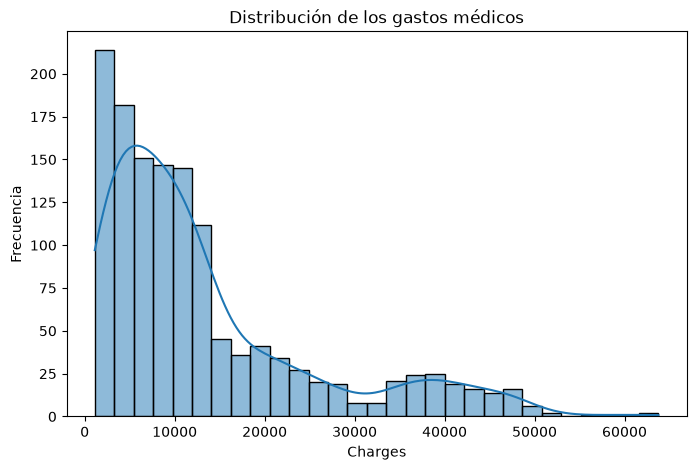

In [32]:
plt.figure(figsize=(8, 5))

sns.histplot(df["charges"], kde=True)

plt.title("Distribución de los gastos médicos")
plt.xlabel("Charges")
plt.ylabel("Frecuencia")

plt.show()

In [60]:
## Distribución edad

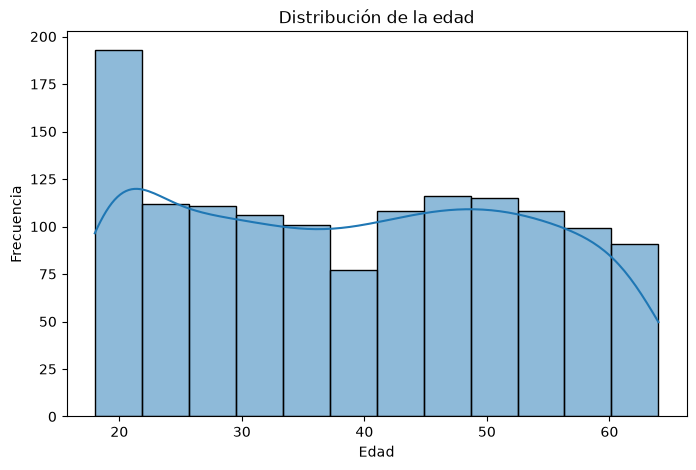

In [59]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    kde=True
)

plt.title("Distribución de la edad")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")

plt.show()

In [33]:
## Analizar la relación entre BMI y charges

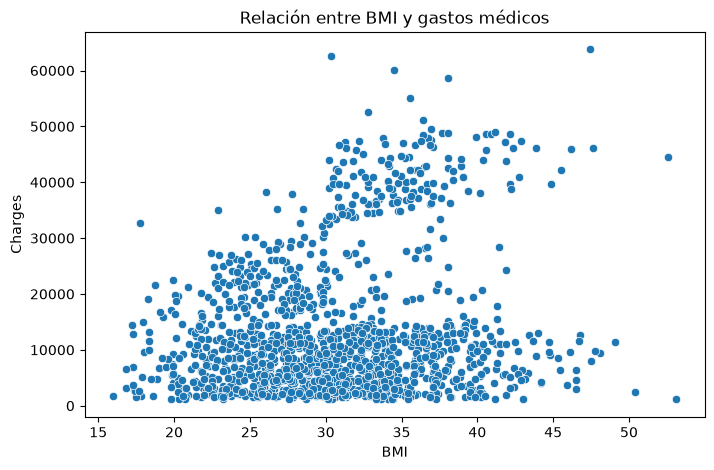

In [34]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="bmi",
    y="charges"
)

plt.title("Relación entre BMI y gastos médicos")
plt.xlabel("BMI")
plt.ylabel("Charges")

plt.show()

In [35]:
## Relación entre edad y charges

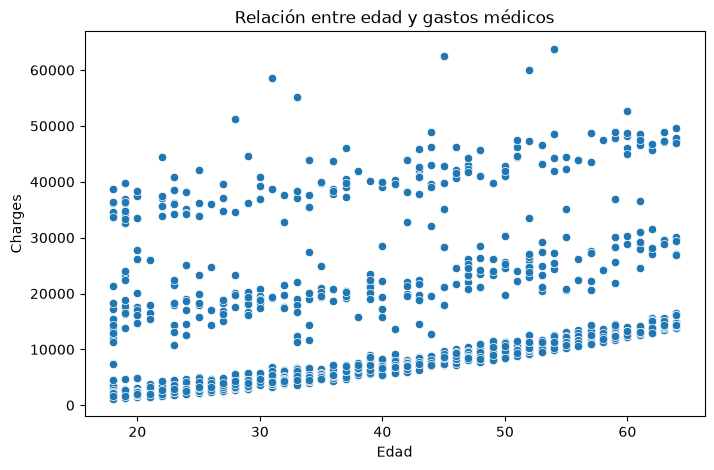

In [36]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="charges"
)

plt.title("Relación entre edad y gastos médicos")
plt.xlabel("Edad")
plt.ylabel("Charges")

plt.show()

In [61]:
## Gastos según fumador

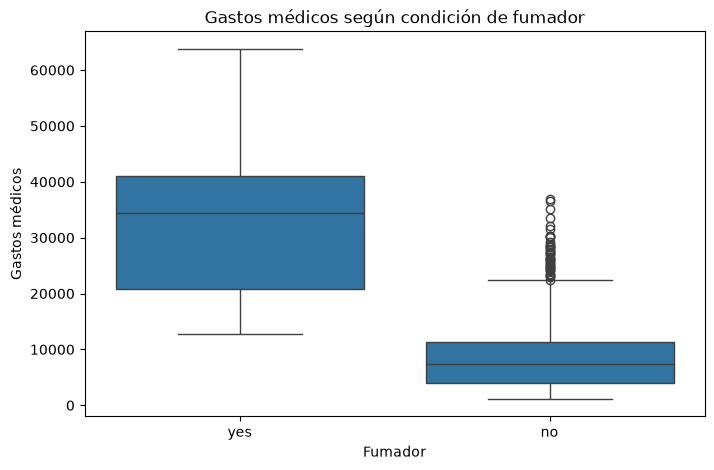

In [62]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="smoker",
    y="charges"
)

plt.title("Gastos médicos según condición de fumador")
plt.xlabel("Fumador")
plt.ylabel("Gastos médicos")

plt.show()

In [65]:
## Matriz de correlación
correlacion = df.select_dtypes(
    include="number"
).corr()

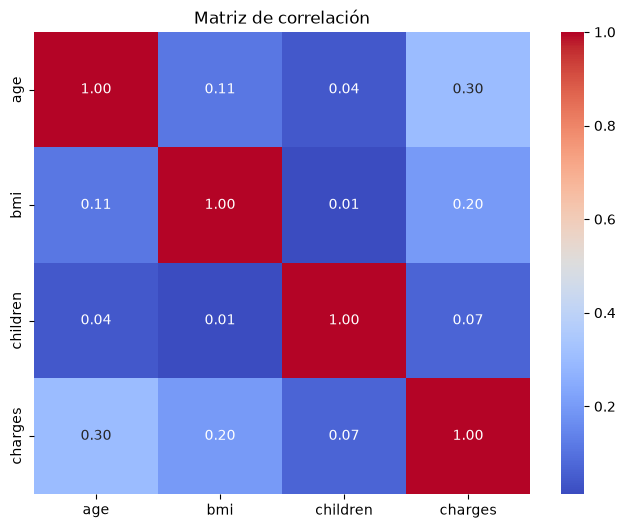

In [66]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlación")

plt.show()

In [38]:
## FASE 3 — Detección de outliers
## Un outlier es un valor que se encuentra muy alejado del comportamiento habitual de los datos.

Método IQR

Uno de los métodos que podemos utilizar es el:

Rango Intercuartílico — IQR

La fórmula es:

IQR = Q3-Q1 $$

Donde:

Q1 = primer cuartil
Q3 = tercer cuartil

Los límites son:

Límite\ inferior = Q1 - 1.5(IQR) $$
Límite superior=Q3+1.5(IQR)


In [67]:
## Calcular Q1
Q1 = df["charges"].quantile(0.25)

print("Q1:", Q1)

Q1: 4746.344


In [68]:
## Calcular Q3
Q3 = df["charges"].quantile(0.75)

print("Q3:", Q3)

Q3: 16657.71745


In [69]:
## Calcular IQR
IQR = Q3 - Q1

print("IQR:", IQR)

IQR: 11911.37345


In [70]:
## Calcular límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

Límite inferior: -13120.716174999998
Límite superior: 34524.777625


In [71]:
## Encontrar los outliers
outliers = df[
    (df["charges"] < limite_inferior) |
    (df["charges"] > limite_superior)
]

print("Cantidad de outliers:", len(outliers))

Cantidad de outliers: 139


In [75]:
## Mostrar los outliers
## Así podremos observar qué registros fueron detectados
outliers

,age,sex,bmi,children,smoker,region,charges
14,27,male,42.130,0,yes,southeast,39611.75770
19,30,male,35.300,0,yes,southwest,36837.46700
23,34,female,31.920,1,yes,northeast,37701.87680
29,31,male,36.300,2,yes,southwest,38711.00000
30,22,male,35.600,0,yes,southwest,35585.57600
...,...,...,...,...,...,...,...
1300,45,male,30.360,0,yes,southeast,62592.87309
1301,62,male,30.875,3,yes,northwest,46718.16325
1303,43,male,27.800,0,yes,southwest,37829.72420
1313,19,female,34.700,2,yes,southwest,36397.57600


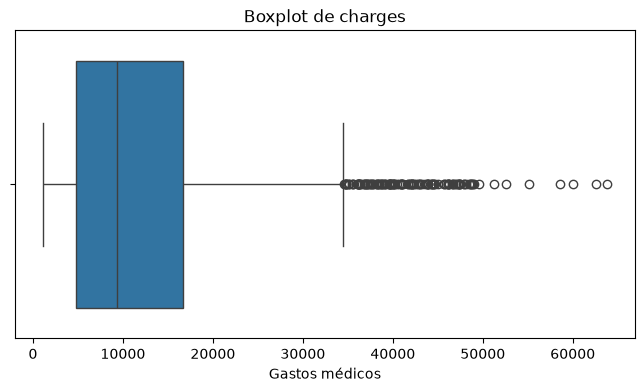

In [77]:
## grafico outlier
plt.figure(figsize=(8, 4))

sns.boxplot(
    x=df["charges"]
)

plt.title("Boxplot de charges")
plt.xlabel("Gastos médicos")

plt.show()

Se identificaron valores atípicos en la variable charges mediante el método IQR. Debido a que estos valores pueden representar gastos médicos reales y no necesariamente errores de registro, no se eliminaron automáticamente. Se conservaron para evitar perder información relevante del fenómeno analizado.

In [45]:
## FASE 4 — Preparación de variables

Tenemos:

Numéricas:
age
bmi
children
charges

Categóricas:
sex
smoker
region

Nuestro modelo matemático necesita trabajar con números.

One-Hot Encoding
convierte los datos en 0 u 1 dependiendo el  caso

In [79]:
## Separar X e y
## Porque charges es justamente lo que queremos predecir
X = df.drop("charges", axis=1)
## Guardamos charges como nuestra variable objetivo.
y = df["charges"]

In [82]:
## Verificar X
X.head()

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


In [83]:
## Verificar y
y.head()

0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [84]:
## Identificar columnas numéricas y categóricas
columnas_numericas = [
    "age",
    "bmi",
    "children"
]

columnas_categoricas = [
    "sex",
    "smoker",
    "region"
]

In [125]:
## FASE 5 — Normalización / estandarización

En esta etapa se aplicará estandarización a las variables numéricas
mediante StandardScaler de scikit-learn.

La estandarización transforma cada variable utilizando su media y
desviación estándar:

z = (x - μ) / σ

De esta manera, las variables numéricas quedan en una escala comparable,
con una media aproximada de 0 y una desviación estándar aproximada de 1.

In [126]:
## el ColumnTransformer nos permite aplicar diferentes transformaciones a diferentes columnas
## La estandarización permite llevarlas a una escala comparable
preprocesador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            StandardScaler(), ## Para las columnas numéricas utiliza StandardScaler, estandariza
            columnas_numericas
        ),
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"), ## handle_unknown="ignore" es importante cuando posteriormente aparezca una categoría que no estaba presente durante el entrenamiento
            columnas_categoricas
        )
    ]
)

In [89]:
## FASE 7 primero — Separar Train/Test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [90]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1069, 6)
X_test: (268, 6)
y_train: (1069,)
y_test: (268,)


In [95]:
## FASE 6 — Selección de atributos

In [97]:
## Crear el pipeline
modelo_pipeline = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador
        ),
        (
            "seleccion",
            SelectKBest(
                score_func=f_regression,
                k="all"
            )
        ),
        (
            "modelo",
            LinearRegression()
        )
    ]
)

In [98]:
## FASE 8 — Entrenamiento

In [101]:
## aprende la relación entre las características y charges
modelo_pipeline.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('seleccion', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of colum

In [104]:
## Obtener predicciones
## el modelo recibe los gastos médicos que el modelo predice
y_pred = modelo_pipeline.predict(X_test)

In [106]:
## FASE 9 — Evaluación

In [107]:
## Mean Absolute Error, Indica el error absoluto promedio
MAE = metrics.mean_absolute_error(
    y_test,
    y_pred
)

print("MAE:", MAE)

MAE: 4177.045561036324


In [108]:
## Mean Squared Error
MSE = metrics.mean_squared_error(
    y_test,
    y_pred
)

print("MSE:", MSE)

MSE: 35478020.675235584


In [110]:
## RMSE
RMSE = np.sqrt(MSE)

print("RMSE:", RMSE)

RMSE: 5956.342894363586


In [112]:
## R²
## nos proporciona una medida de qué tan bien explica el modelo la variabilidad observada en los datos de prueba.
R2 = metrics.r2_score(
    y_test,
    y_pred
)

print("R²:", R2)

R²: 0.8069287081198013


In [113]:
## Mostrar todas las métricas
print("========== EVALUACIÓN DEL MODELO ==========")
print(f"MAE  : {MAE:.2f}")
print(f"MSE  : {MSE:.2f}")
print(f"RMSE : {RMSE:.2f}")
print(f"R²   : {R2:.4f}")

========== EVALUACIÓN DEL MODELO ==========
MAE  : 4177.05
MSE  : 35478020.68
RMSE : 5956.34
R²   : 0.8069


In [114]:
## Tabla de valores reales y predichos
comparacion = pd.DataFrame({
    "Real": y_test.values,
    "Predicho": y_pred
})

comparacion.head(10)

,Real,Predicho
0,8688.85885,8143.693884
1,5708.86700,5737.115683
2,11436.73815,14369.314876
3,38746.35510,31745.513636
4,4463.20510,8962.386657
5,9304.70190,13149.722353
6,38511.62830,30446.760679
7,2150.46900,1453.288813
8,7345.72660,10633.018402
9,10264.44210,11318.943794


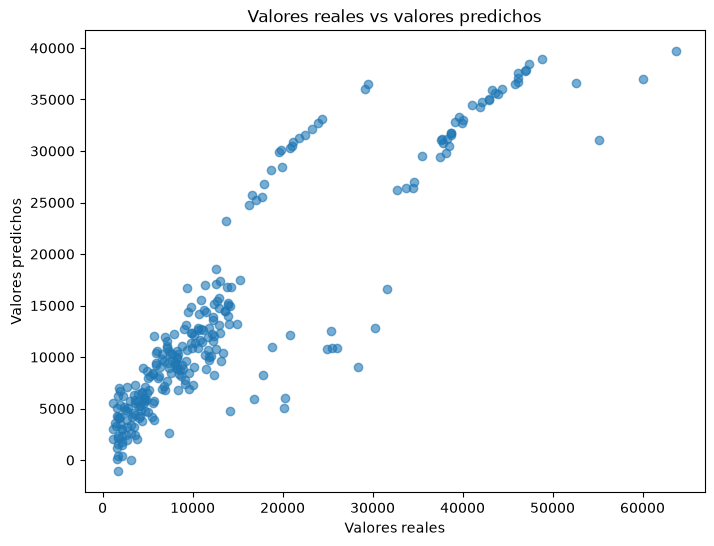

In [115]:
## Gráfico Real vs Predicho
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

plt.xlabel("Valores reales")
plt.ylabel("Valores predichos")
plt.title("Valores reales vs valores predichos")

plt.show()

In [116]:
## FASE 6 — Analizar selección de atributos

In [117]:
## named_steps nos permite acceder a una etapa específica del Pipeline
selector = modelo_pipeline.named_steps["seleccion"]

In [118]:
## Obtener las puntuaciones
puntuaciones = selector.scores_

print(puntuaciones)

[9.77463518e+01 3.50914926e+01 7.98232624e+00 3.87661585e+00
 3.87661585e+00 1.59570326e+03 1.59570326e+03 1.07529898e-01
 3.23213859e+00 6.68859674e+00 1.38485757e+00]


In [119]:
## Obtener nombres de las características transformadas
preprocesador_entrenado = (
    modelo_pipeline
    .named_steps["preprocesamiento"]
)

nombres_features = (
    preprocesador_entrenado
    .get_feature_names_out()
)

In [120]:
tabla_features = pd.DataFrame({
    "Caracteristica": nombres_features,
    "Puntuacion": puntuaciones
})

tabla_features = tabla_features.sort_values(
    by="Puntuacion",
    ascending=False
)

tabla_features

,Caracteristica,Puntuacion
6,categoricas__smoker_yes,1595.703256
5,categoricas__smoker_no,1595.703256
0,numericas__age,97.746352
1,numericas__bmi,35.091493
2,numericas__children,7.982326
9,categoricas__region_southeast,6.688597
4,categoricas__sex_male,3.876616
3,categoricas__sex_female,3.876616
8,categoricas__region_northwest,3.232139
10,categoricas__region_southwest,1.384858


In [121]:
## FASE 10 — Predicción con nuevos datos

In [127]:
nuevo_paciente = pd.DataFrame({
    "age": [35],
    "sex": ["male"],
    "bmi": [28.5],
    "children": [1],
    "smoker": ["no"],
    "region": ["southeast"]
})

In [128]:
prediccion = modelo_pipeline.predict(
    nuevo_paciente
)

print("Gasto médico estimado:")
print(f"${prediccion[0]:,.2f}")

Gasto médico estimado:
$6,270.26
